In [1]:
%matplotlib inline

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import statsmodels
import statsmodels.api as sm
from statsmodels.formula.api import ols

# Write your imports here
from scipy.stats import ttest_rel

# Hypothesis Testing Exercise: Part 1
## Comparing Distributions. Testing statistical hypotheses. p-value. Goodness of fit

### Problem 1. t-test
You're given a dataset which describes the age at death among members of the sovereignty, aristocracy, and gentry. There is an explanation [here](http://www.stat.ufl.edu/~winner/data/agedeath.txt) and the actual data is [here](http://www.stat.ufl.edu/~winner/data/agedeath.dat). Get to know the data; plot histograms and / or boxplots, or other graphs as needed. Note that all ages are only for a certain social class of people and they won't represent the entire population of people.

Do the mean ages differ significantly ($\alpha = 5\%$)? Perform a t-test. Do you need an independent or paired test?

In [3]:
# Write your code here

Let's try something else. In the data/horse_beginners.dat file, there's data about 8 people. Each person is a beginner in horse riding. They were asked to imagine how long their ride would take (for a fixed track length). After that, the actual times were measured.

Get acquainted with the data and draw some plots if you need (hint: boxplots are useful for comparing distributions). Are the people good at predicting their ride times? That is, are there significant differences between imagined and actual time (5%-level)? Also, is the imagined time significantly longer than the real time? Perform a t-test. Don't forget that the subjects are the same.

In [4]:
# Write your code here
rides = pd.read_csv("data/horse_beginners.dat", sep=r"\s+")

predicted = rides["Imaginary"]
actual = rides["Actual"]

print(rides[["Imaginary", "Actual"]].mean())
print("Двустранен тест:", ttest_rel(predicted, actual))
print("Предвиденото време е по-дълго:",
      ttest_rel(predicted, actual, alternative="greater"))

Imaginary    27.70875
Actual       69.89875
dtype: float64
Двустранен тест: TtestResult(statistic=np.float64(-6.190025790155937), pvalue=np.float64(0.00044960248190267684), df=np.int64(7))
Предвиденото време е по-дълго: TtestResult(statistic=np.float64(-6.190025790155937), pvalue=np.float64(0.9997751987590486), df=np.int64(7))


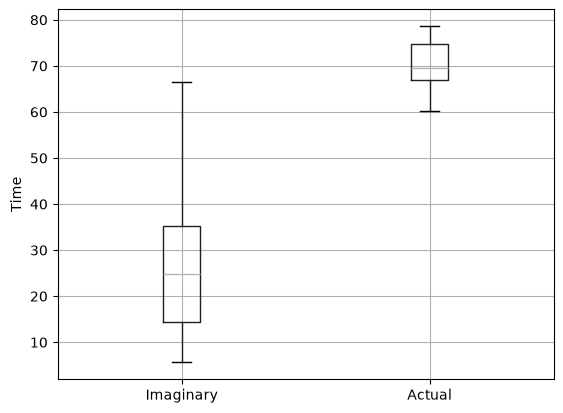

In [5]:
rides.boxplot(column=["Imaginary", "Actual"])
plt.ylabel("Time")
plt.show()

# Conclusion

A paired t-test was used because each of the eight riders provided both an estimated time and an actual time.

At the 5% significance level, the two-sided test shows a significant difference between the mean estimated and actual times (p = 0.00045). The riders underestimated their times by 42.19 time units on average (27.71 estimated versus 69.90 actual).

The one-sided test provides no evidence that the mean estimated time is longer than the mean actual time (p = 0.9998).

### Problem 2. ANOVA
Read [this](http://www.itl.nist.gov/div898/education/anova/newcar.dat) dataset. Get acquainted with it and plot graphics. Note that it's formatted a bit oddly. First, you have to skip some rows; second, the target variable is first (in most datasets, it's the last one). Well, that shouldn't bother you :).

Do the rates differ significantly ($\alpha = 0,05$) between cities? Apply one-way ANOVA to find out.

**Hint:** You have to group all values by city. You can get a dictionary of groups like this:
```python
groups = { k: v.tolist() for k, v in cars.groupby("City").Rate }
```

After that, you can use ```*groups.values()``` to pass all dictionary values as separate arguments to a function.

,count,mean
City,,
1,9,13.194444
2,9,12.611111
3,9,13.306667
4,9,13.244444
5,9,13.483333
6,9,12.200000


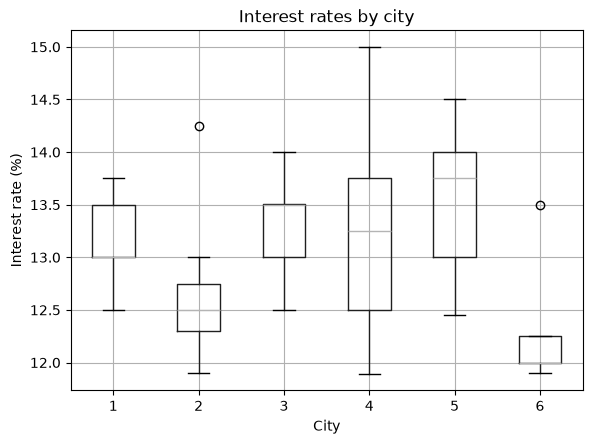

F = 4.8294, p = 0.001175


In [6]:
# Write your code here
from scipy.stats import f_oneway

cars = pd.read_csv(
    "data/newcar.dat",
    sep=r"\s+",
    skiprows=25,
    header=None,
    names=["Rate", "City"],
)

rates_by_city = cars.groupby("City")["Rate"]
display(rates_by_city.agg(["count", "mean"]))

cars.boxplot(column="Rate", by="City")
plt.title("Interest rates by city")
plt.suptitle("")
plt.ylabel("Interest rate (%)")
plt.show()

city_groups = [rates for _, rates in rates_by_city]
result = f_oneway(*city_groups)
print(f"F = {result.statistic:.4f}, p = {result.pvalue:.6f}")

**Conclusion**

A one-way ANOVA showed a statistically significant difference in
mean interest rates among the six cities (F = 4.8294, p = 0.001175).
At the 5% significance level, we reject the null hypothesis that
all six population means are equal.

Well, most analyses aren't so simple. Let's have a look at another dataset. This one is located [here](http://www.itl.nist.gov/div898/education/anova/ratfeed.dat). Get acquainted with it.

This time, we've got two explanatory variables: amount and type of diet.

Perform one-way ANOVA to each variable separately, disregarding the other one. 

To do this, take for example the "Amount" variable. Group all weights by amount, disregarding the diet type. Perform ANOVA on the groups, like you did before. Repeat the same process with "Diet".

Do the groups differ significantly at the 5%-level?

In [7]:
# Write your code here
rats = pd.read_csv(
    "data/ratfeed.dat",
    sep=r"\s+",
    skiprows=25,
    header=None,
    names=["Weight", "Amount", "Diet"],
)

for factor in ["Amount", "Diet"]:
    print(factor)
    groups = rats.groupby(factor)["Weight"]
    display(groups.agg(["count", "mean"]))

    result = f_oneway(*(weights for _, weights in groups))
    print(f"F = {result.statistic:.4f}, p = {result.pvalue:.6f}")

Amount


,count,mean
Amount,,
1,30,95.133333
2,30,80.600000


F = 14.1021, p = 0.000403
Diet


,count,mean
Diet,,
1,20,89.6
2,20,89.1
3,20,84.9


F = 0.4768, p = 0.623234


**Conclusion**

Two separate one-way ANOVAs were performed at the 5% significance level.
Mean weight gain differed significantly between the two food amounts
(F = 14.1021, p = 0.000403). The high-amount group gained an average
of 95.13 g, compared with 80.60 g in the low-amount group.

The test for diet type did not find a statistically significant
difference in mean weight gain (F = 0.4768, p = 0.623234).

Sometimes we have to take into account multiple values. In this case, we want to ask another question: Is there a significant difference between combinations of diet and amount? These are called **interacting variables**. Unfortunately, there isn't a quick and easy way to perform this test in `scipy.stats`, but `statsmodels` is another library which will come in handy.

We won't go into many details how it works but you basically create a linear model (`ols` stands for "ordinary least squares") and you provide a formula. The formula we want to use looks like this:
```python
formula = "Weight ~ C(Amount) + C(Diet) + C(Amount):C(Diet)"
```

`Weight`, `Amount` and `Diet` are the **column names** (i.e. variable names) in the dataset. `C(Amount)` tells the library to treat the variable as *categorical*, not numerical (e.g. diet 1 + diet 3 makes absolutely no sense). Finally `C(Amount):C(Diet)` means that we take the interaction between these categories (Cartesian product - every amount with every diet).

How do we read this formula? "The Weight column is proportional to the categories Amount, Diet and their interaction" (i.e. Weight is a linear combination of the three other variables).

We are now ready. Well, we could have done all this by hand as well, but why bother :)? Just create the linear model:
```python
model = ols(formula, rats).fit()
```

and the ANOVA table:
```python
table = statsmodels.stats.anova.anova_lm(model, typ = 2)
```

You can see there's "type 2" ANOVA chosen. If you're interested, you can read more about the three types of ANOVA [here](https://mcfromnz.wordpress.com/2011/03/02/anova-type-iiiiii-ss-explained/)

P. S.: The type of formulas we described above are typical for another popular language for statistics and data analysis, called **R**. They're also why many people hate R. They're good but need a bit of understanding and getting accustomed to. Case closed :D.

In [8]:
# Write your code here
from statsmodels.stats.anova import anova_lm

model = ols("Weight ~ C(Amount) * C(Diet)", data=rats).fit()
display(anova_lm(model, typ=2))

display(rats.groupby(["Diet", "Amount"])["Weight"].mean().unstack())

,sum_sq,df,F,PR(>F)
C(Amount),3168.266667,1.0,14.766649,0.000322
C(Diet),266.533333,2.0,0.621129,0.541132
C(Amount):C(Diet),1178.133333,2.0,2.745520,0.073188
Residual,11586.000000,54.0,NaN,NaN


Amount,1,2
Diet,,
1,100.0,79.2
2,99.5,78.7
3,85.9,83.9


**Conclusion**

At the 5% significance level, the two-way ANOVA found a significant
main effect of food amount (p = 0.000322). The main effect of diet type
was not statistically significant (p = 0.541132).

The interaction between food amount and diet type was not statistically
significant, F(2, 54) = 2.7455, p = 0.073188.

### Problem 3. Contingency Tables. $\chi^2$-test
Have a look at the dataset `data/Popular Kids.tsv` and its description `data/Popular Kids Description.txt`.

When we want to compare data across many categories, a useful way we can visualize it, is using **contingency tables** (or two-way tables). One variable goes to the rows, another one - to the columns of the table. The intersection cell represents the number of observations having this combination of values.

Try it now:
```python
pd.crosstab(kids.Grade, kids.Goals)
```

You can also specify multiple columns - this will create higher-dimensional tables. Keep in mind, however, that these are difficult to look at and understand. We're usually fine with two variables, three in some rare cases.

In [9]:
# Write your code here
kids = pd.read_csv("data/Popular Kids.tsv", sep="\t")

grade_goals = pd.crosstab(kids["Grade"], kids["Goals"])
display(grade_goals)

Goals,Grades,Popular,Sports
Grade,,,
4,63,31,25
5,88,55,33
6,96,55,32


The **$\chi^2$**-test provides a way to test for association between two (or more) categorical variables. In this case, **Grade** and **Goals** seem to be good candidates. This is most easily done using the contingency table. Fortunately, `scipy.stats` has one such method (read the docs [here](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2_contingency.html)).

Note that this test doesn't specify what the relationship is. It just tells us that there might be a significant relationship.

Are goals related to grade? To what extent? Are these significant?
* $H_0$: No relation between Grade and Goals
* $H_1$: Some relation exists between Grade and Goals
* $\alpha = 0,05$

In [10]:
# Write your code here
from scipy.stats import chi2_contingency

grade_test = chi2_contingency(grade_goals)
n = grade_goals.to_numpy().sum()
min_dim = min(grade_goals.shape) - 1
cramers_v = np.sqrt(grade_test.statistic / (n * min_dim))

print(f"χ² = {grade_test.statistic:.4f}, p = {grade_test.pvalue:.6f}")
print(f"Cramér's V = {cramers_v:.3f}")

χ² = 1.3121, p = 0.859319
Cramér's V = 0.037


**Conclusion**

The chi-square test found no statistically significant association
between grade level and students’ chosen goals at the 5% significance
level (χ²(4) = 1.3121, p = 0.859319). Cramér’s V = 0.037 indicates
a very weak association in the sample.

The school areas are also divided into "Urban", "Suburban" and "Rural". Are the school areas related to goals? Perform the same type of test. Is the difference significant now?

In [11]:
# Write your code here
area_goals = pd.crosstab(kids["Urban/Rural"], kids["Goals"])
display(area_goals)

area_test = chi2_contingency(area_goals)
print(f"χ² = {area_test.statistic:.4f}, p = {area_test.pvalue:.6f}")

Goals,Grades,Popular,Sports
Urban/Rural,,,
Rural,57,50,42
Suburban,87,42,22
Urban,103,49,26


χ² = 18.8276, p = 0.000850


**Conclusion**

The chi-square test found a statistically significant association
between school area and students’ chosen goals at the 5% significance
level (χ²(4) = 18.8276, p = 0.000850). In the sample, students in
rural areas chose sports more often than students in suburban or
urban areas.

Feel free to continue exploring the dataset as you wish. You can find interesting data and relationships. 

**Note:** You'll see the catch of categorical variables - these are very difficult to visualize properly. Most plots just appear as symmetrical patterns of dots. You can rely on contingency tables and correlations to properly describe and explore these variables.